# Insurance Pricing Analytics — walkthrough

**Question:** what should a driver pay for French motor third-party liability insurance,
depending on age and Bonus-Malus — and how reliable is that price?

**Data:** freMTPL2, a public French motor portfolio: 678,013 policies (`freMTPL2freq`)
and 26,639 claim amounts (`freMTPL2sev`).

**How this notebook works:** it tells the story of the project and calls the functions
of the project modules (`data_prep`, `eda`, `frequency`, `severity`, `pricing`, `metrics`).
The code lives in the modules, not here, so notebook and scripts can never drift apart.
Every number below is computed, none is typed in.

| Step | Module / script |
|---|---|
| 1. Data, consistency check, cleaning | `data_prep.py` (and in SQL: `policies_analysis.sql`) |
| 2. Exploratory analysis | `eda.py` |
| 3. Claim frequency: Poisson GLM | `frequency.py` |
| 4. Claim severity: Gamma vs. lognormal | `severity.py` |
| 5. Tariff and in-sample check | `pricing.py` |
| 6. Out-of-sample validation, large losses | `validation.py` |
| 7. Additional rating factors, credibility | `features.py` |

In [1]:
import warnings
import pandas as pd
from IPython.display import display, Image

import data_prep, eda, frequency, severity, pricing
from metrics import (split_by_policy, fit_frequency, fit_frequency_agg,
                     poisson_deviance, gini, lift_table, plot_lift)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)


class ShowFigures:
    """Stands in for the PDF file of main.py: the modules call savefig(fig),
    here the figure is shown in the notebook instead."""
    def savefig(self, fig, **kwargs):
        display(fig)


show = ShowFigures()

## 1. Data: why the first model was 32% too high

The first version of this project modelled claim frequency with a Poisson GLM and claim
severity with a Gamma GLM. On portfolio level, frequency × severity overestimated the
observed claim cost by **+31.9%**. The cause was not the model but the data:
claim counts (`ClaimNb`) and claim amounts did not describe the same claims.

In [2]:
policies_raw, claims_raw = data_prep.load_raw()
data_prep.consistency_report(policies_raw, claims_raw)

sum of ClaimNb: 36,102 | claim amounts: 26,639 | ratio 1.355
                     policies  policy_years  ClaimNb  claims_with_amount  share_with_amount  frequency
block IDpol < 24952      9387     4800.1774     9942               307.0             0.0309     2.0712
rest of portfolio      668626   353699.2680    26160             26137.0             0.9991     0.0740

claims without a policy: 195 on 6 policy numbers
         claims     total  neighbours_exist
IDpol                                      
2262511      66  151801.0              True
2282134      36  330920.0              True
2227533      25   64094.0              True
2220367      24   84442.0              True
2277846      23   73441.0              True
2286775      21   84017.0              True

policies with more than 4 claims:
    IDpol  ClaimNb  Exposure  DrivAge  BonusMalus VehBrand                      Region
  19471.0       11      1.00       65          50       B2                      Centre
  93954.0        5 

**What the check shows**

- A **block of claim-only policies** at the start of the data (all policies before the first
  claim-free policy) holds about a quarter of all `ClaimNb`, but almost no claim amounts,
  with an implausible frequency of about 2 claims per year. Outside the block, counts and
  amounts match for more than 99.9%.
- The **claims without a policy** belong to only six policy numbers with dozens of claims each;
  their neighbouring numbers exist, so these are gaps in the policy table.
- Several **policies with more than 4 claims** share one driver profile — most likely a fleet,
  not individual private drivers.

**Cleaning rules** (implemented identically in Python and SQL, cross-checked by
`check_sql_cleaning.py`): remove the whole block (removing only its claim policies would bias
the frequency downwards), remove remaining inconsistent policies and fleet-like risks,
cap exposure at one year, keep only claims that belong to a kept policy.

In [3]:
policies, claims = data_prep.clean(policies_raw, claims_raw)
policies = data_prep.add_tariff_groups(policies)
claims_rated = claims.merge(policies[["IDpol", "age_group", "bm_group"]], on="IDpol")
print(f"sum of ClaimNb = {policies['ClaimNb'].sum():,} = number of claim amounts = {len(claims):,}")

cleaning: 678,013 -> 668,595 policies, 26,639 -> 26,065 claims (block IDpol < 24952 removed)
sum of ClaimNb = 26,065 = number of claim amounts = 26,065


## 2. Exploratory analysis

The claim frequency is **claims per policy year**: `sum(ClaimNb) / sum(Exposure)`.
The mean of `ClaimNb` is not the frequency, because policies are insured for different
parts of a year.

French Bonus-Malus: 50 is the best value (0.5 × base premium), 100 the starting level,
above 100 a malus after claims — the opposite direction to the German SF classes.


Claim frequency: overview
         policies  share_%
ClaimNb                   
0          643953    96.31
1           23291     3.48
2            1284     0.19
3              62     0.01
4               5     0.00

claims: 26,065 | policy years: 353,540 | annual claim frequency: 0.0737
mean exposure per policy: 0.529 years
ClaimNb: mean 0.0390, variance 0.0420, variance / mean 1.08


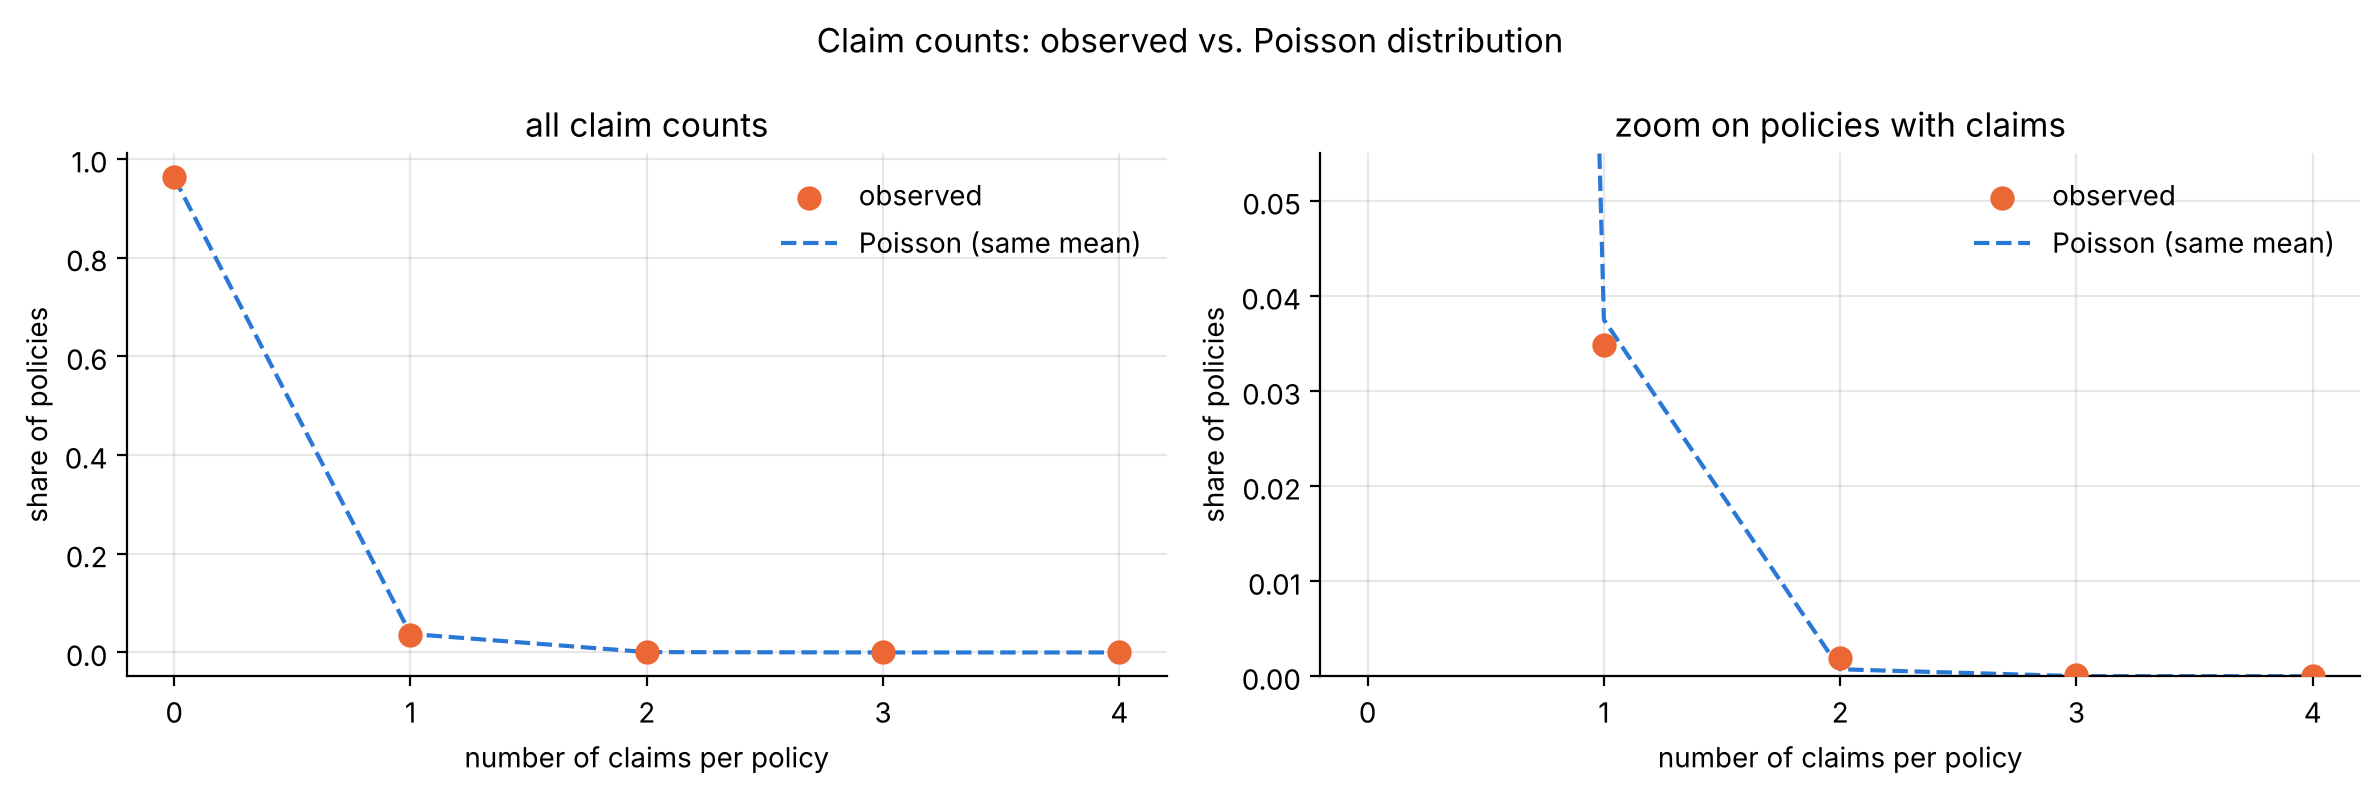


Claim frequency by rating factor (one-way)



frequency by age_group:
           policies  claims  policy_years  frequency  relativity
age_group                                                       
18-25         38482    2391    16079.8641     0.1487      2.0169
26-40        233337    8132   112207.0952     0.0725      0.9830
41-60        295716   11661   161463.2193     0.0722      0.9796
61+          101060    3881    63789.9394     0.0608      0.8252

frequency by bm_group:
          policies  claims  policy_years  frequency  relativity
bm_group                                                       
<=50        377873   11335   221510.8330     0.0512      0.6941
51-64       123439    5460    61893.3662     0.0882      1.1965
65-80        87660    3938    38266.3192     0.1029      1.3959
81-100       71910    4079    28323.9461     0.1440      1.9534
101-125       6907    1090     3173.6006     0.3435      4.6586
>125           806     163      372.0529     0.4381      5.9424


In [4]:
portfolio_frequency = eda.frequency_overview(policies, show)
age_freq, bm_freq = eda.frequency_one_way(policies, portfolio_frequency)

Young drivers have about twice the portfolio frequency; Bonus-Malus separates even more
strongly. Claim amounts are extremely skewed:


Claim severity: overview
count      26065.00
mean        2267.13
std        29575.63
min            1.00
25%          688.26
50%         1172.00
75%         1205.36
max      4075400.56
Name: ClaimAmount, dtype: float64
missing amounts: 0 | amounts <= 0: 0


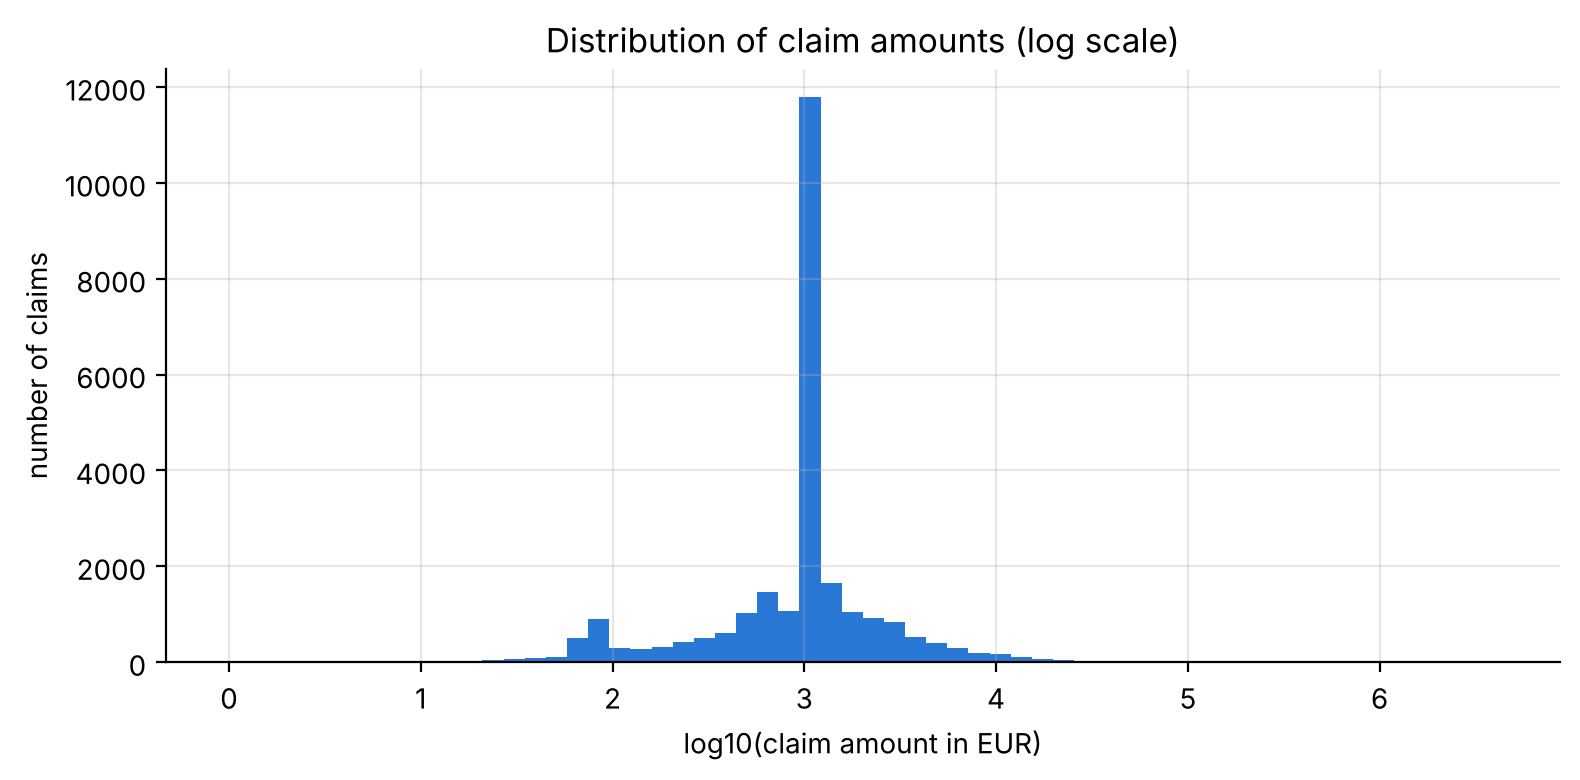


claims above threshold:
  >    10,000 EUR:   470 claims (1.803%)
  >    50,000 EUR:    86 claims (0.330%)
  >   100,000 EUR:    41 claims (0.157%)
  >   500,000 EUR:     4 claims (0.015%)
  > 1,000,000 EUR:     3 claims (0.012%)
largest 10 claims: [4075401, 1403057, 1301173, 774412, 390742, 369132, 307096, 301635, 287423, 281897]

Claim severity by rating factor (one-way)

severity by age_group:
           claims    mean  median
age_group                        
18-25        2391  5140.0  1172.0
26-40        8132  2121.0  1128.0
41-60       11661  1785.0  1172.0
61+          3881  2255.0  1172.0
quantiles:
             0.50    0.75    0.90    0.95     0.99
age_group                                         
18-25      1172.0  1318.0  3204.0  5560.0  23086.0
26-40      1128.0  1248.0  2876.0  4905.0  15620.0
41-60      1172.0  1204.0  2672.0  4556.0  15077.0
61+        1172.0  1204.0  2601.0  4368.0  17518.0
tail growth (ratio of neighbouring quantiles):
           75% / 50%  90% / 75% 

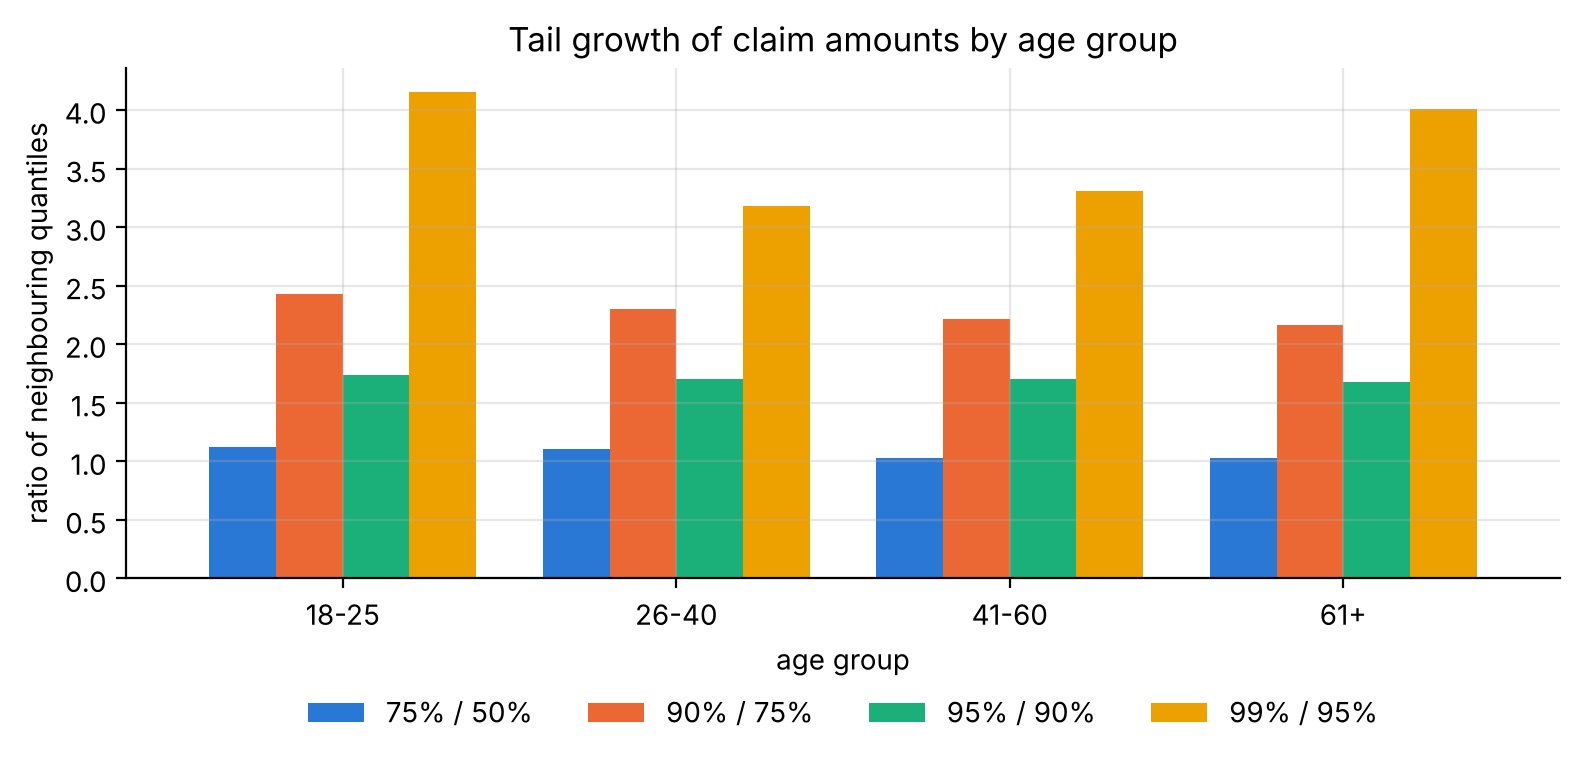


severity by bm_group:
          claims    mean  median
bm_group                        
<=50       11335  1912.0  1172.0
51-64       5460  2028.0  1172.0
65-80       3938  2039.0  1172.0
81-100      4079  3863.0  1172.0
101-125     1090  1846.0  1172.0
>125         163  3340.0  1172.0
quantiles:
            0.50    0.75    0.90    0.95     0.99
bm_group                                         
<=50      1172.0  1210.0  2671.0  4534.0  15013.0
51-64     1172.0  1204.0  2728.0  4849.0  16628.0
65-80     1172.0  1208.0  2896.0  4863.0  15230.0
81-100    1172.0  1301.0  3045.0  5217.0  21592.0
101-125   1172.0  1204.0  2256.0  3858.0  15104.0
>125      1172.0  1204.0  3404.0  5546.0  37293.0
tail growth (ratio of neighbouring quantiles):
          75% / 50%  90% / 75%  95% / 90%  99% / 95%
bm_group                                            
<=50           1.03       2.21       1.70       3.31
51-64          1.03       2.27       1.78       3.43
65-80          1.03       2.40       1.68  

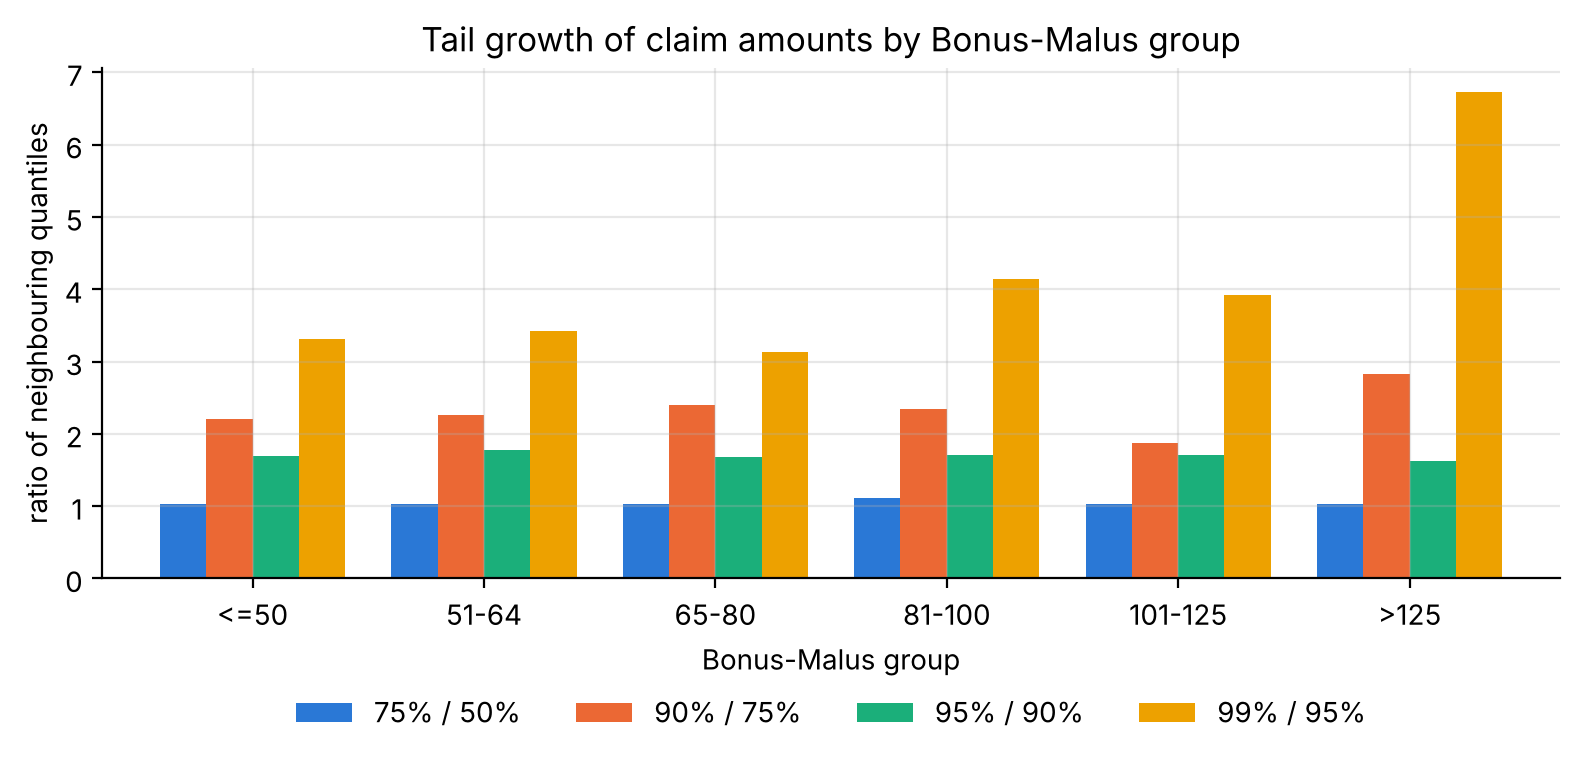

In [5]:
eda.severity_overview(claims, show)
age_sev, bm_sev = eda.severity_one_way(claims_rated, show)

**Medians are almost the same in every group, the means are not.** The difference comes from
the right tail: up to the 95% quantile the groups behave alike, above it the claims of young
drivers grow much faster. All three claims above €1 million belong to drivers aged 18–20.

## 3. Claim frequency: Poisson GLM

$$\log E[\text{ClaimNb}] = \log(\text{Exposure}) + \beta_0 + \beta_\text{age} + \beta_\text{BM}$$

`log(Exposure)` is an **offset** (coefficient fixed at 1), so the model describes claims per
policy year. `exp(β)` is a multiplicative tariff factor relative to the reference group
(age 18–25, Bonus-Malus ≤50).


Claim frequency: Poisson GLM (age group + Bonus-Malus group)



tariff factors (Intercept = annual frequency of the reference group):
                     coefficient  factor  p_value
Intercept                 -3.085   0.046      0.0
age_group[T.26-40]        -0.204   0.815      0.0
age_group[T.41-60]         0.196   1.216      0.0
age_group[T.61+]           0.107   1.113      0.0
bm_group[T.51-64]          0.685   1.985      0.0
bm_group[T.65-80]          0.865   2.375      0.0
bm_group[T.81-100]         1.188   3.280      0.0
bm_group[T.101-125]        2.047   7.748      0.0
bm_group[T.>125]           2.270   9.676      0.0
Pearson chi2 / df: 1.656
Bonus-Malus 81-100 vs <=50: one-way ratio 2.81, GLM factor at equal age 3.28


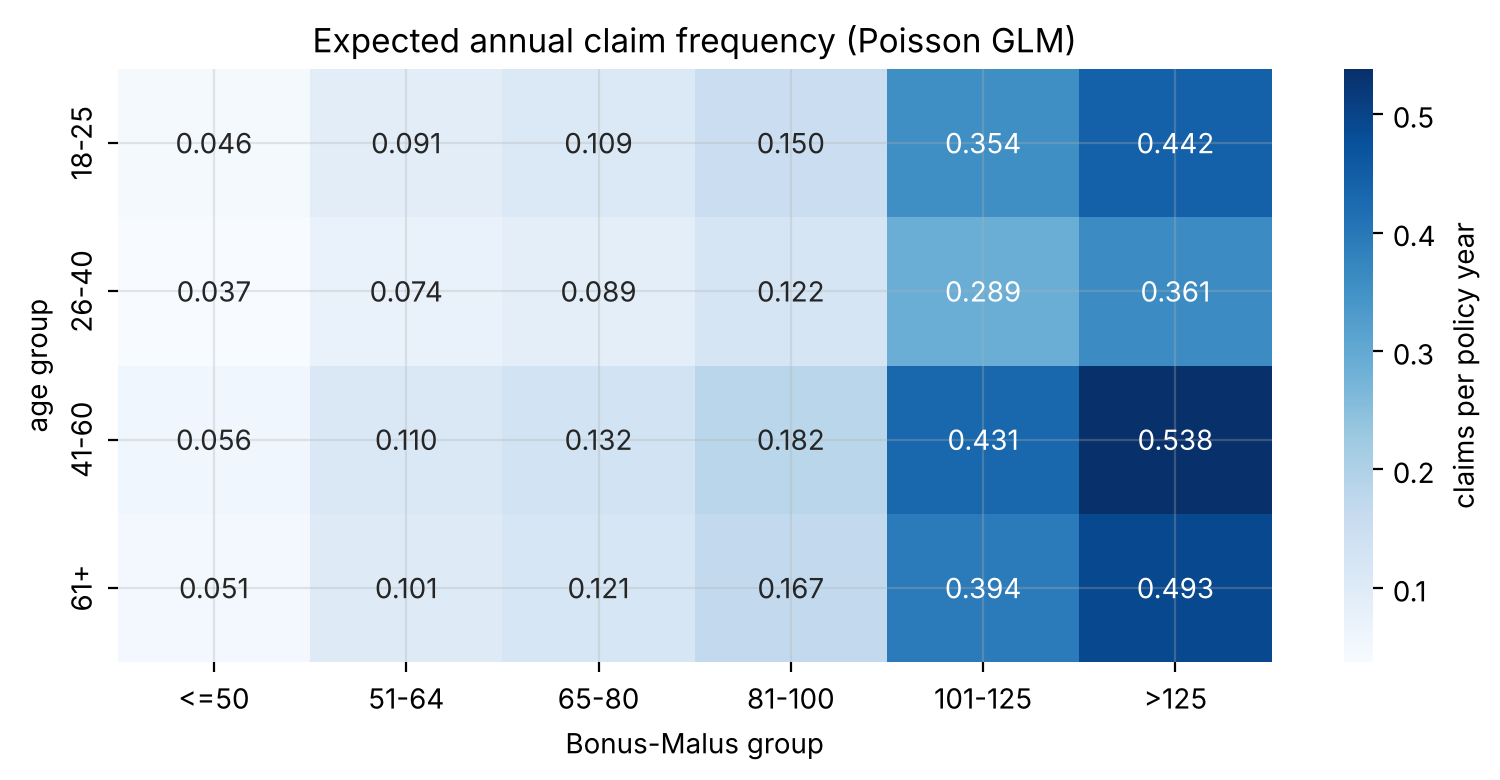

bm_group,<=50,51-64,65-80,81-100,101-125,>125
age_group,,,,,,
18-25,0.045724,0.090749,0.108601,0.149961,0.354287,0.442446
26-40,0.037285,0.074000,0.088558,0.122284,0.288899,0.360787
41-60,0.055611,0.110371,0.132083,0.182386,0.430891,0.538113
61+,0.050905,0.101032,0.120906,0.166953,0.394429,0.492578


In [6]:
poisson_model = frequency.fit_poisson(policies, verbose=False)
frequency.plot_frequency_heatmap(poisson_model, policies, show)

The GLM measures each factor **at equal values of the other factor**: the Bonus-Malus effect
is larger than in the one-way table, because there young drivers (high Bonus-Malus) mix an
age effect into it.

## 4. Claim severity: Gamma GLM vs. lognormal model

The Gamma GLM models the expected claim amount directly. The lognormal model regresses
`log(amount)`; its back-transformation needs the bias correction
$E[Y] = \exp(\mu + \sigma^2/2)$, because $\exp(E[\log Y])$ is the median, not the mean.


Claim severity: Gamma GLM (log link)



severity factors (reference: age 18-25, Bonus-Malus <=50):
                       factor  p_value
Intercept            4356.980    0.000
age_group[T.26-40]      0.473    0.000
age_group[T.41-60]      0.405    0.000
age_group[T.61+]        0.514    0.001
bm_group[T.51-64]       1.030    0.799
bm_group[T.65-80]       0.976    0.855
bm_group[T.81-100]      1.248    0.134
bm_group[T.101-125]     0.761    0.240
bm_group[T.>125]        1.094    0.869

observed vs. Gamma GLM mean claim amount per tariff cell:
                    claims  observed  predicted  relative_error_%
age_group bm_group                                               
18-25     <=50          60    1353.2     4357.0             222.0
          51-64         34    1789.4     4488.5             150.8
          65-80        325    2269.4     4250.8              87.3
          81-100      1492    6967.9     5436.4             -22.0
          101-125      424    1553.0     3315.9             113.5
          >125          56   

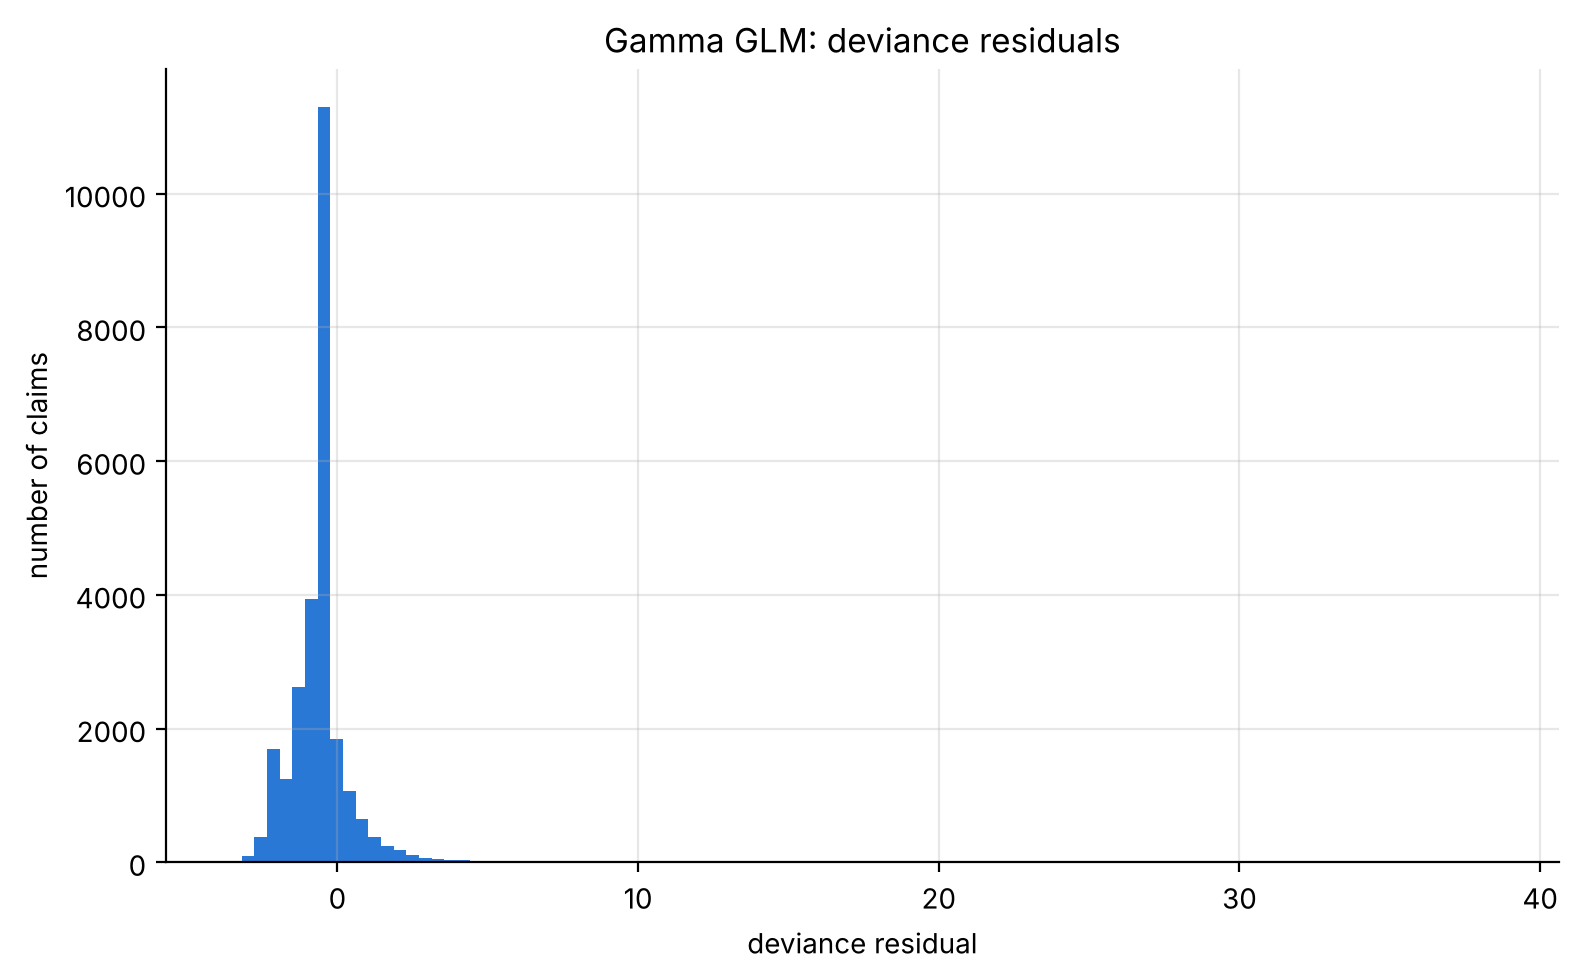

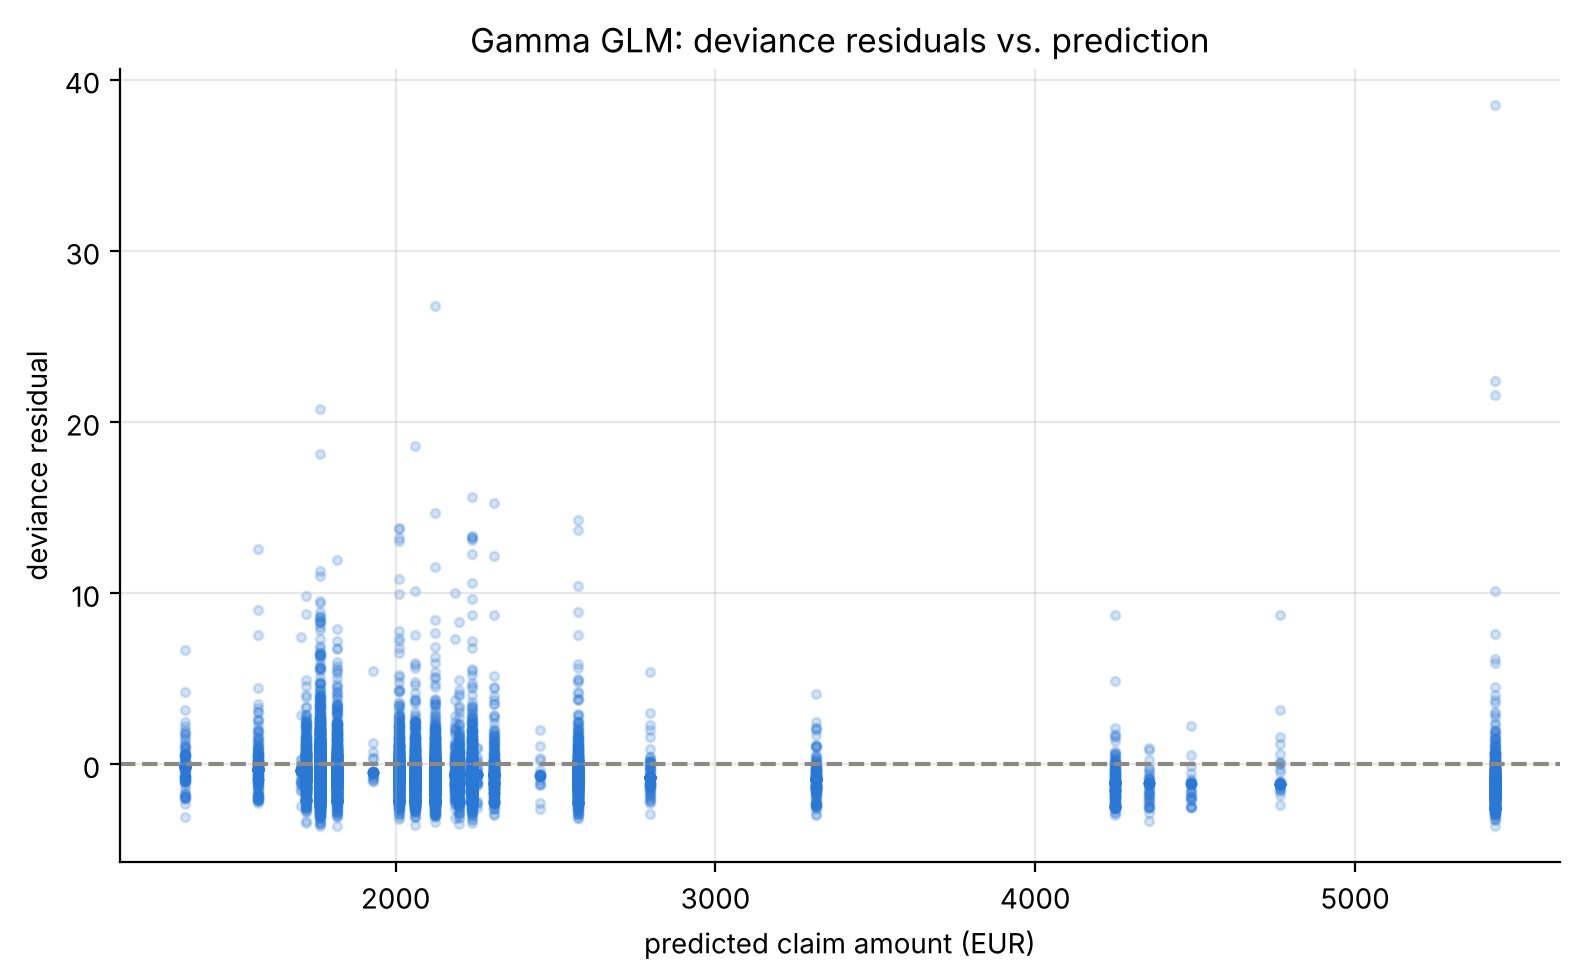


Claim severity: lognormal model (OLS on log claim amount)

factors on the median claim amount with 95% confidence interval:
                      factor  lower_95  upper_95
Intercept            778.169   732.994   826.129
age_group[T.26-40]     1.024     0.968     1.083
age_group[T.41-60]     1.144     1.079     1.213
age_group[T.61+]       1.247     1.168     1.332
bm_group[T.51-64]      1.082     1.043     1.124
bm_group[T.65-80]      1.155     1.106     1.206
bm_group[T.81-100]     1.255     1.197     1.316
bm_group[T.101-125]    1.359     1.261     1.464
bm_group[T.>125]       1.487     1.248     1.772


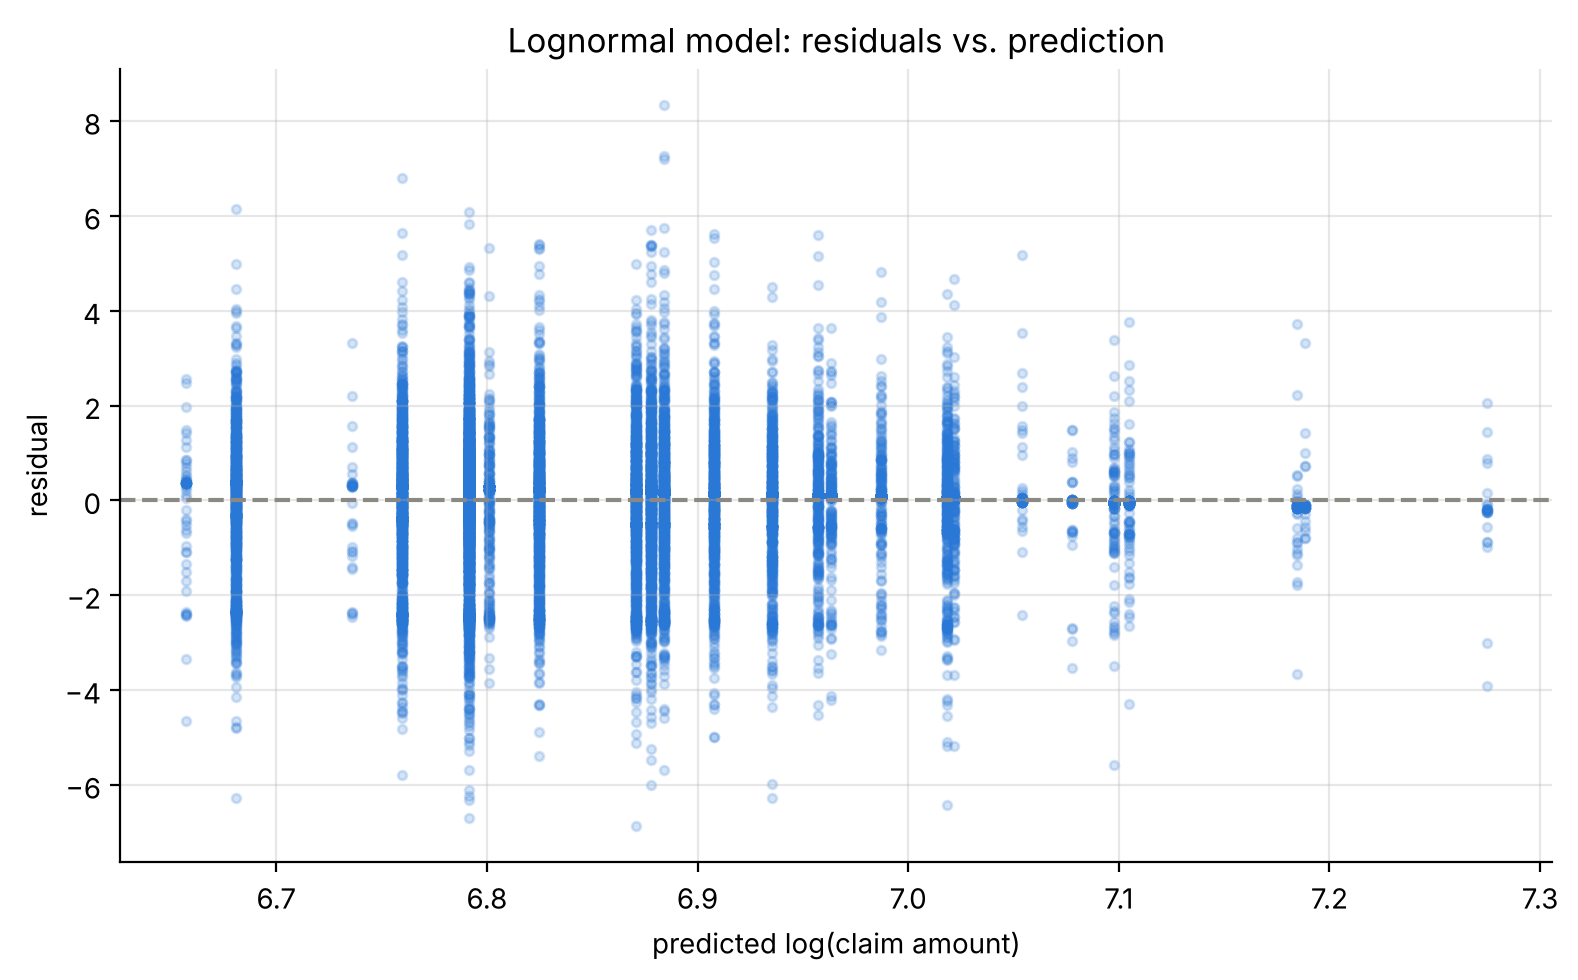

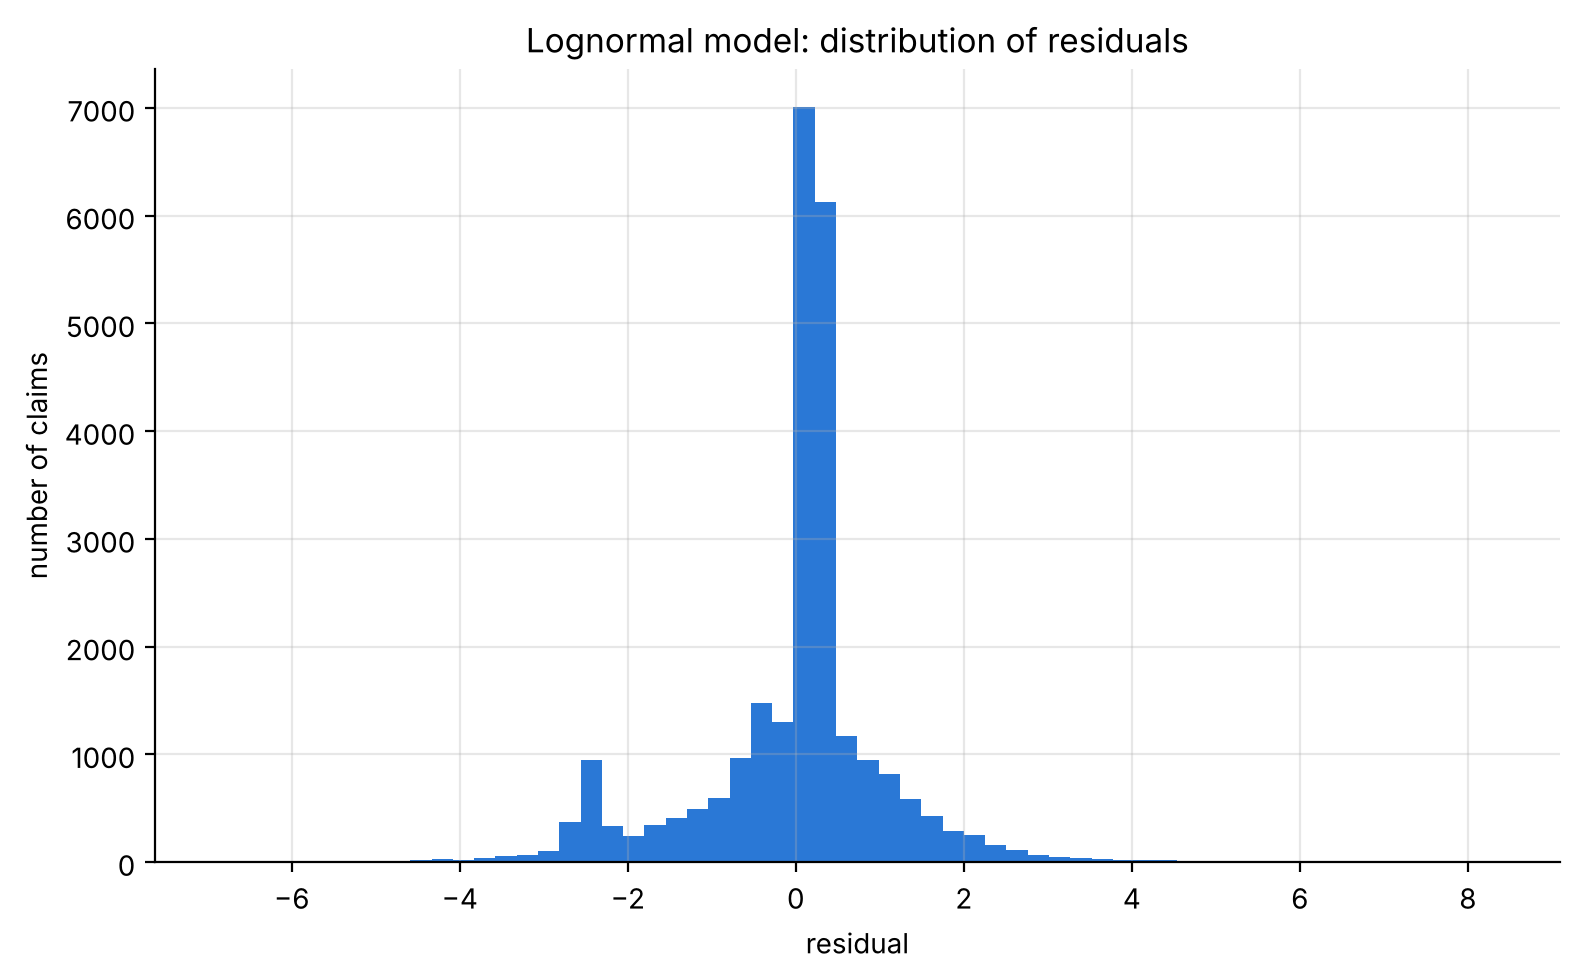

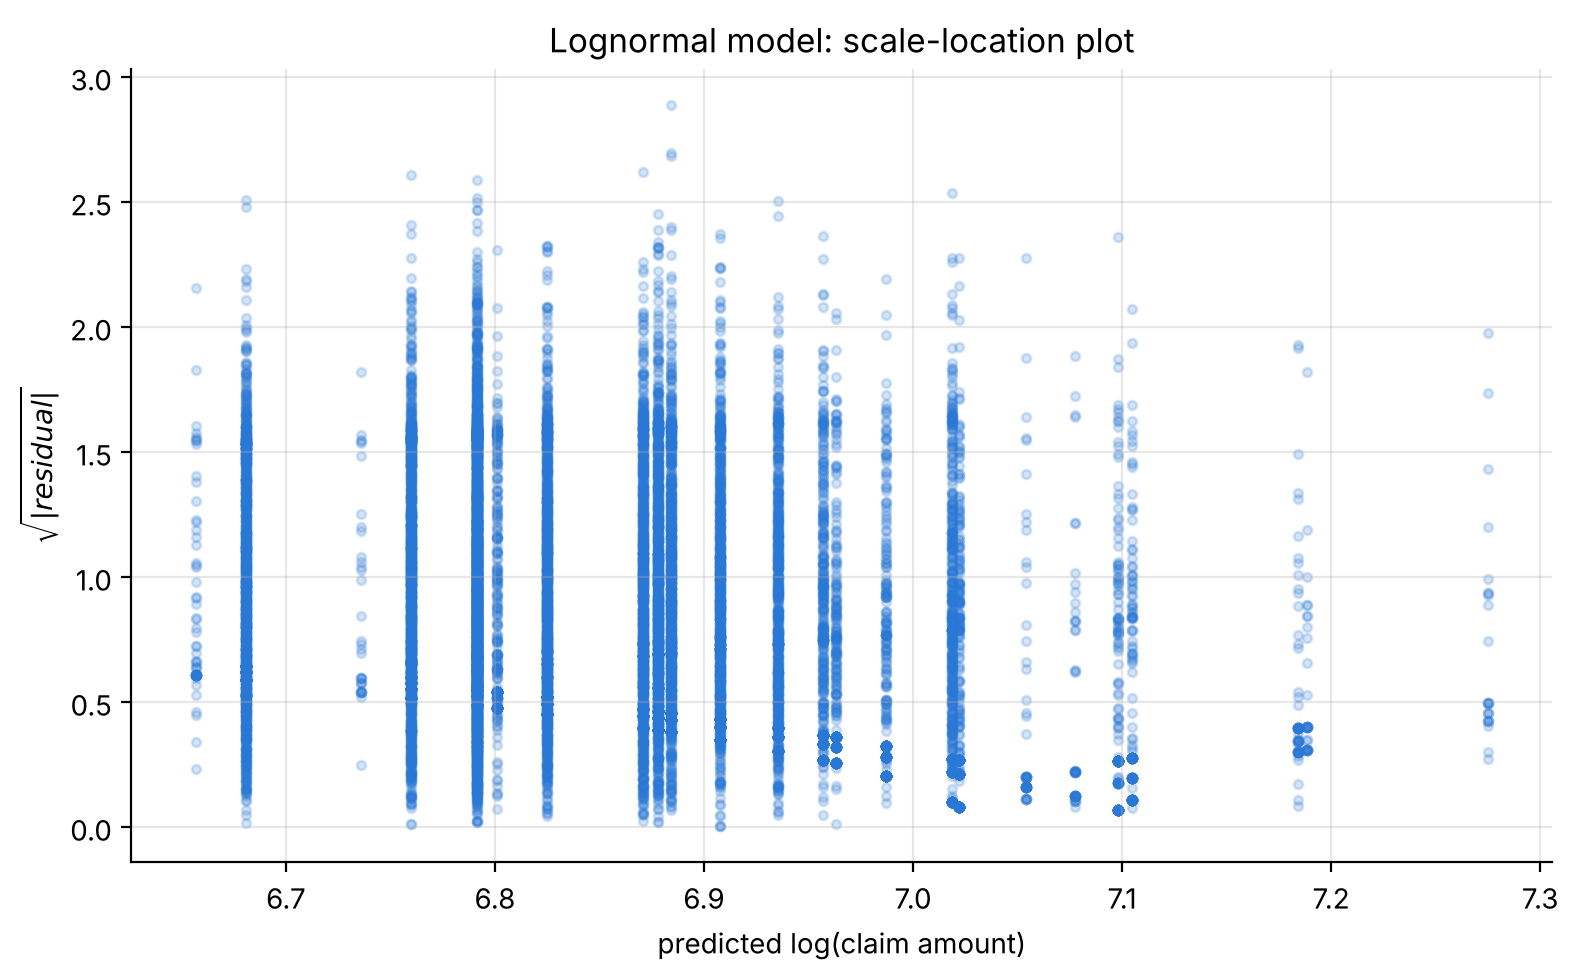

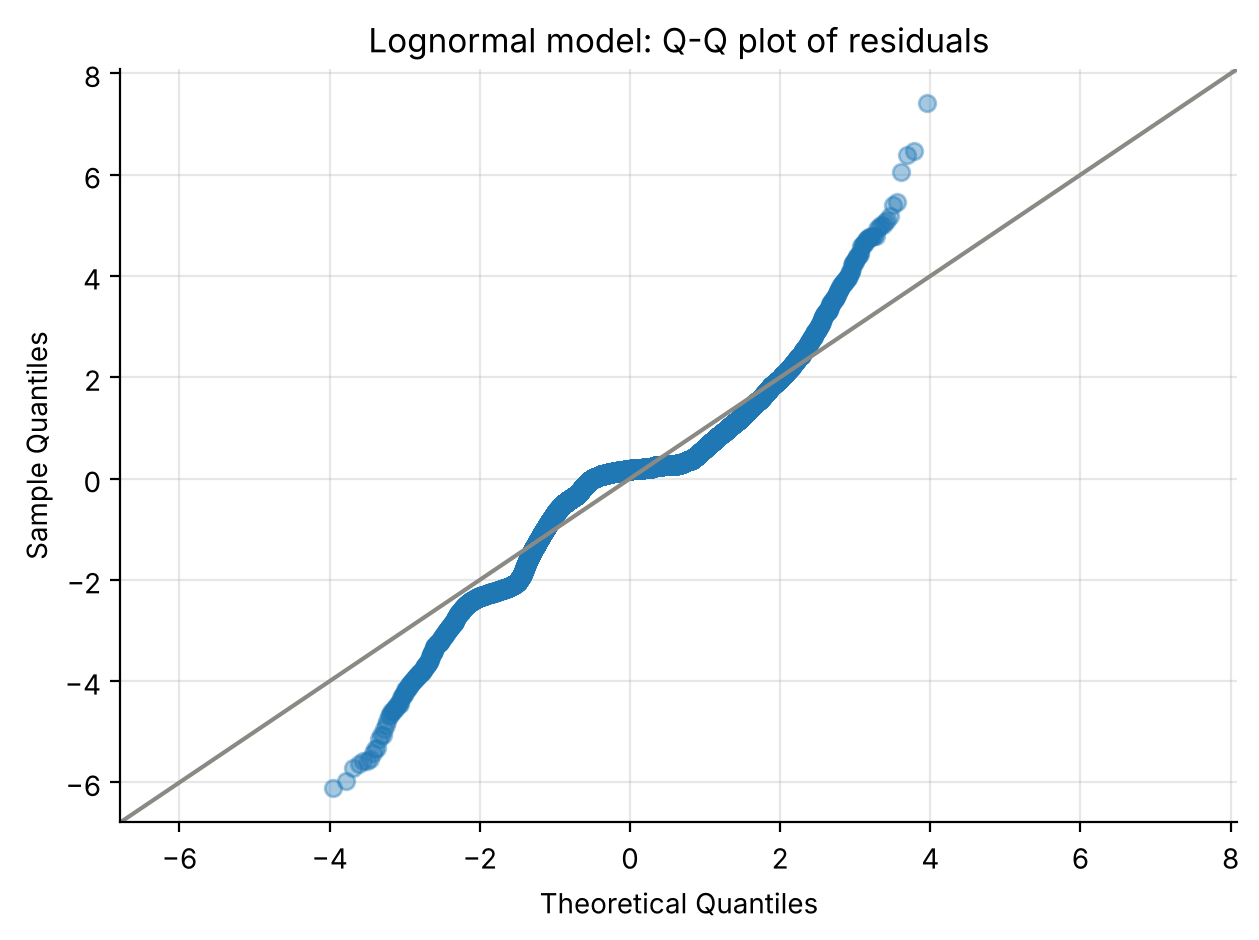


Claim severity: Gamma vs. lognormal
mean claim amount: observed 2267.13, Gamma 2252.29, lognormal 1778.19

by age_group:
           claims  observed_mean  gamma_mean  lognormal_mean
age_group                                                   
18-25        2391        5139.60     4842.94         1840.26
26-40        8132        2120.56     2144.38         1700.62
41-60       11661        1784.50     1792.52         1772.10
61+          3881        2254.69     2263.79         1920.77
WMRAE Gamma 1.14% | WMRAE lognormal 14.58%


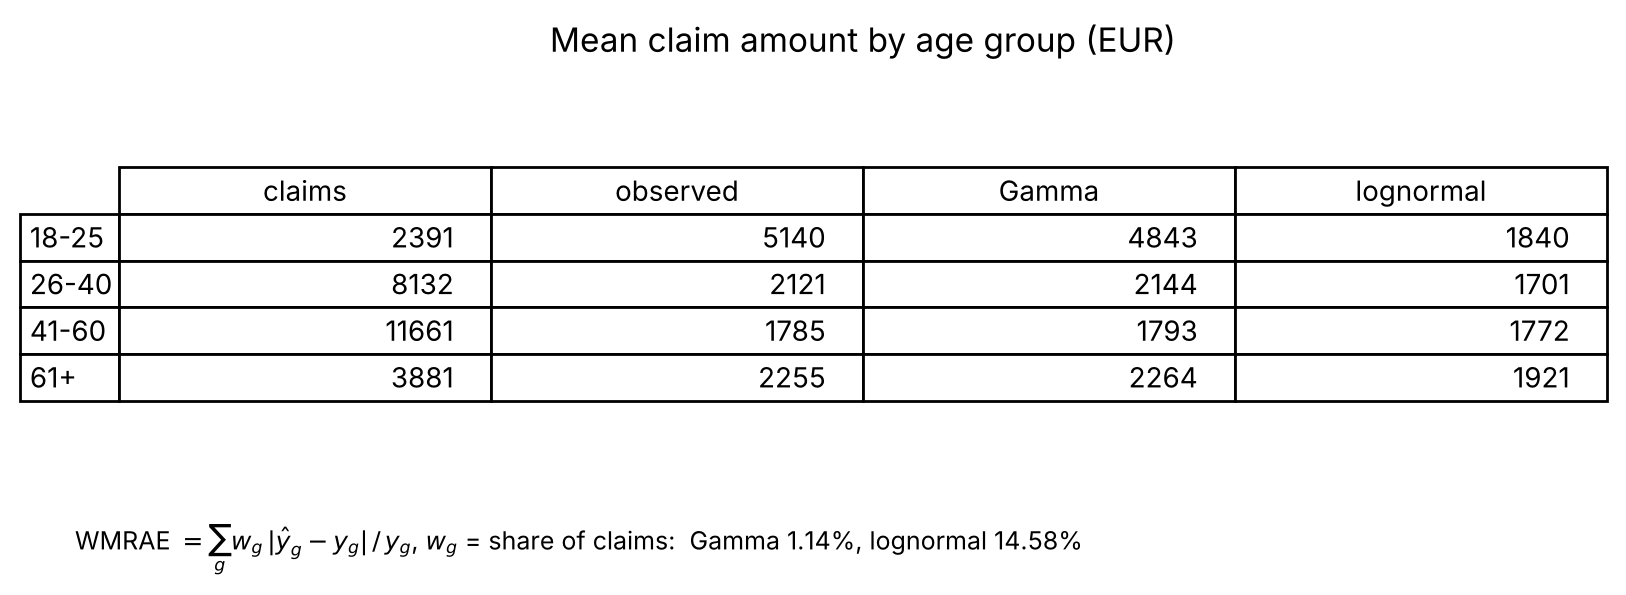


by bm_group:
          claims  observed_mean  gamma_mean  lognormal_mean
bm_group                                                   
<=50       11335        1912.37     1925.84         1681.57
51-64       5460        2027.77     2032.38         1753.78
65-80       3938        2039.34     2123.47         1826.98
81-100      4079        3863.00     3555.08         1926.54
101-125     1090        1845.76     2214.68         2089.61
>125         163        3339.58     3081.67         2340.53
WMRAE Gamma 3.11% | WMRAE lognormal 18.24%


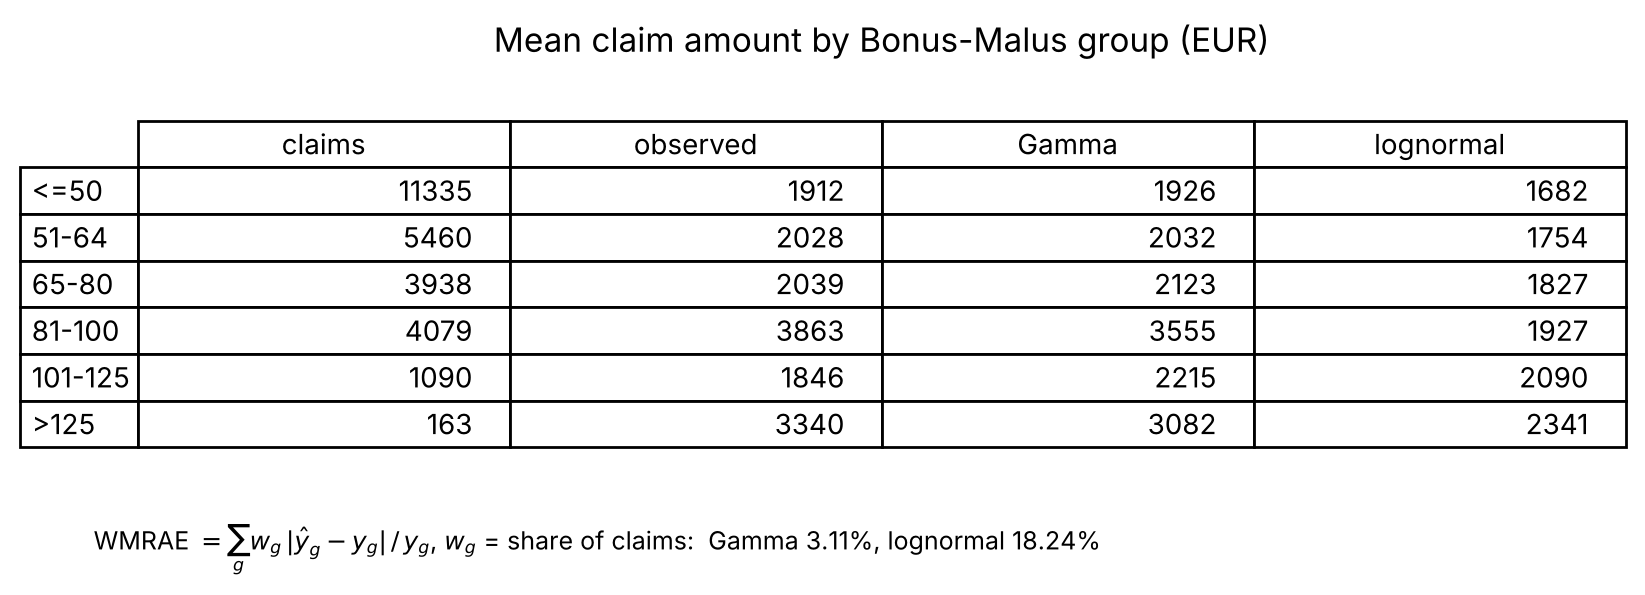


Gamma dispersion: phi (Pearson) = 47.34 -> coefficient of variation 6.88; deviance / df = 1.64


In [7]:
gamma_model = severity.fit_gamma(claims_rated, show, verbose=False)
lognormal_model = severity.fit_lognormal(claims_rated, show, verbose=False)
comparison = severity.compare_models(claims_rated, gamma_model, lognormal_model, show)

The Gamma GLM reproduces the mean claim amount per group much better than the lognormal
model, although the lognormal model shows the Bonus-Malus effect with smaller p-values:
**statistical significance is not the same as a good estimate of the mean** — and pricing needs
the mean.

## 5. Tariff: pure premium per tariff cell

pure premium = expected annual frequency × expected claim amount, for the 4 × 6 = 24 cells.


Tariff: pure premium per tariff cell
age_group bm_group  policies  policy_years  frequency  severity  pure_premium
    18-25     <=50      1108       595.180      0.046  4356.980       199.220
    18-25    51-64       940       572.375      0.091  4488.489       407.327
    18-25    65-80      9872      4629.425      0.109  4250.777       461.640
    18-25   81-100     23769      9028.715      0.150  5436.366       815.243
    18-25  101-125      2514      1131.765      0.354  3315.918      1174.785
    18-25     >125       279       122.404      0.442  4766.698      2109.008
    26-40     <=50     68506     39275.086      0.037  2060.803        76.838
    26-40    51-64     73821     35997.887      0.074  2123.006       157.103
    26-40    65-80     54500     22567.466      0.089  2010.571       178.051
    26-40   81-100     33295     12933.343      0.122  2571.341       314.434
    26-40  101-125      2909      1299.518      0.289  1568.392       453.106
    26-40     >125       3

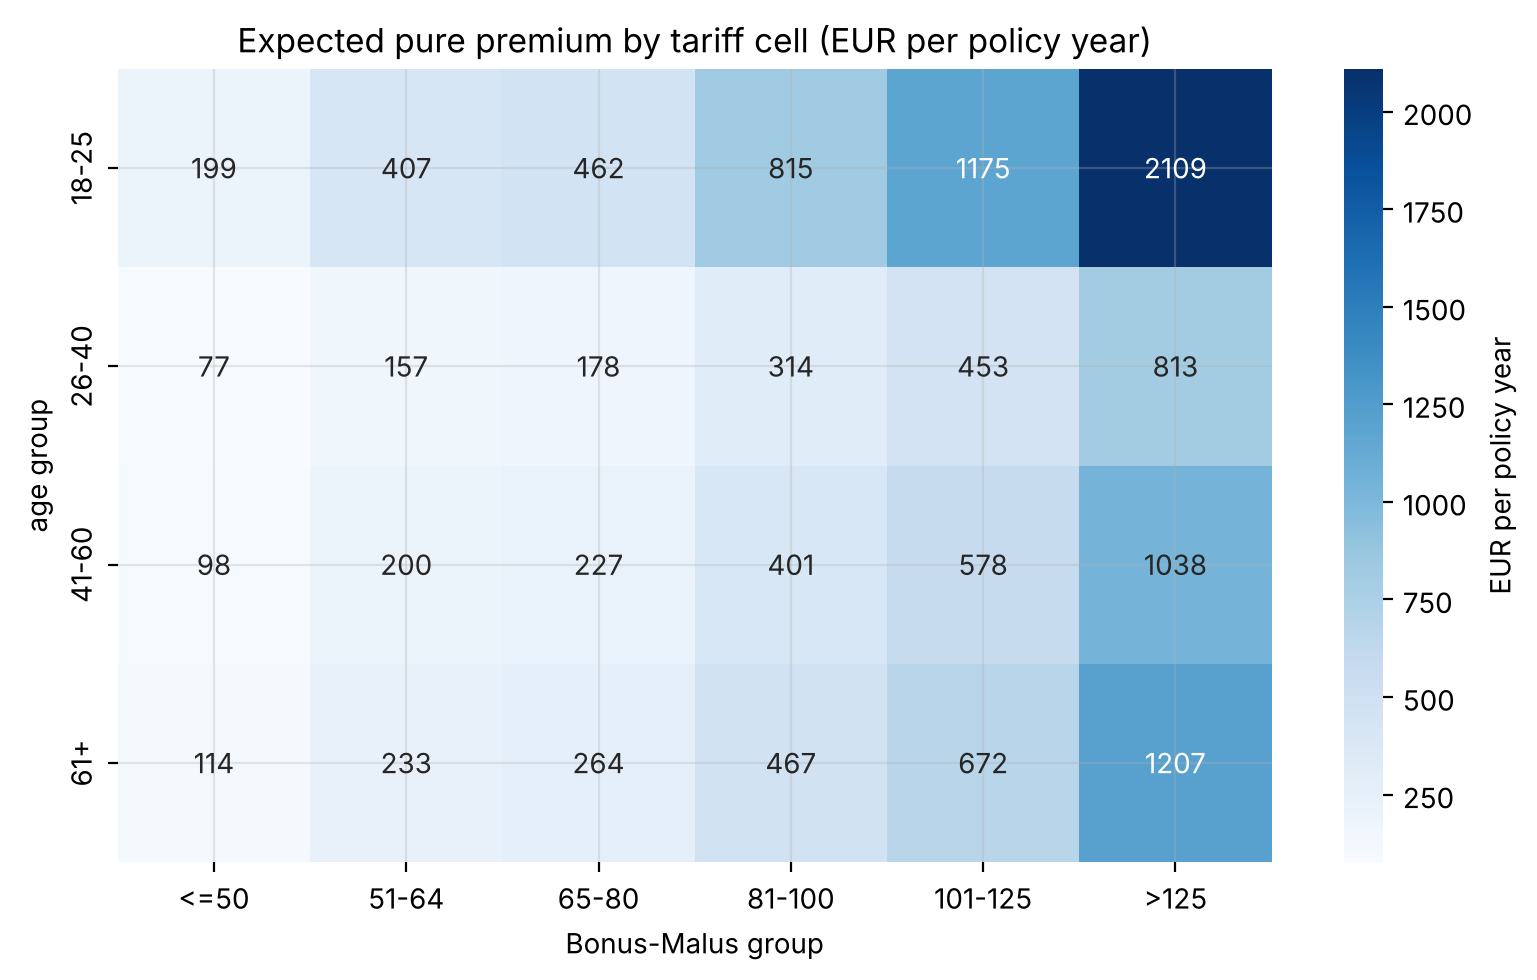

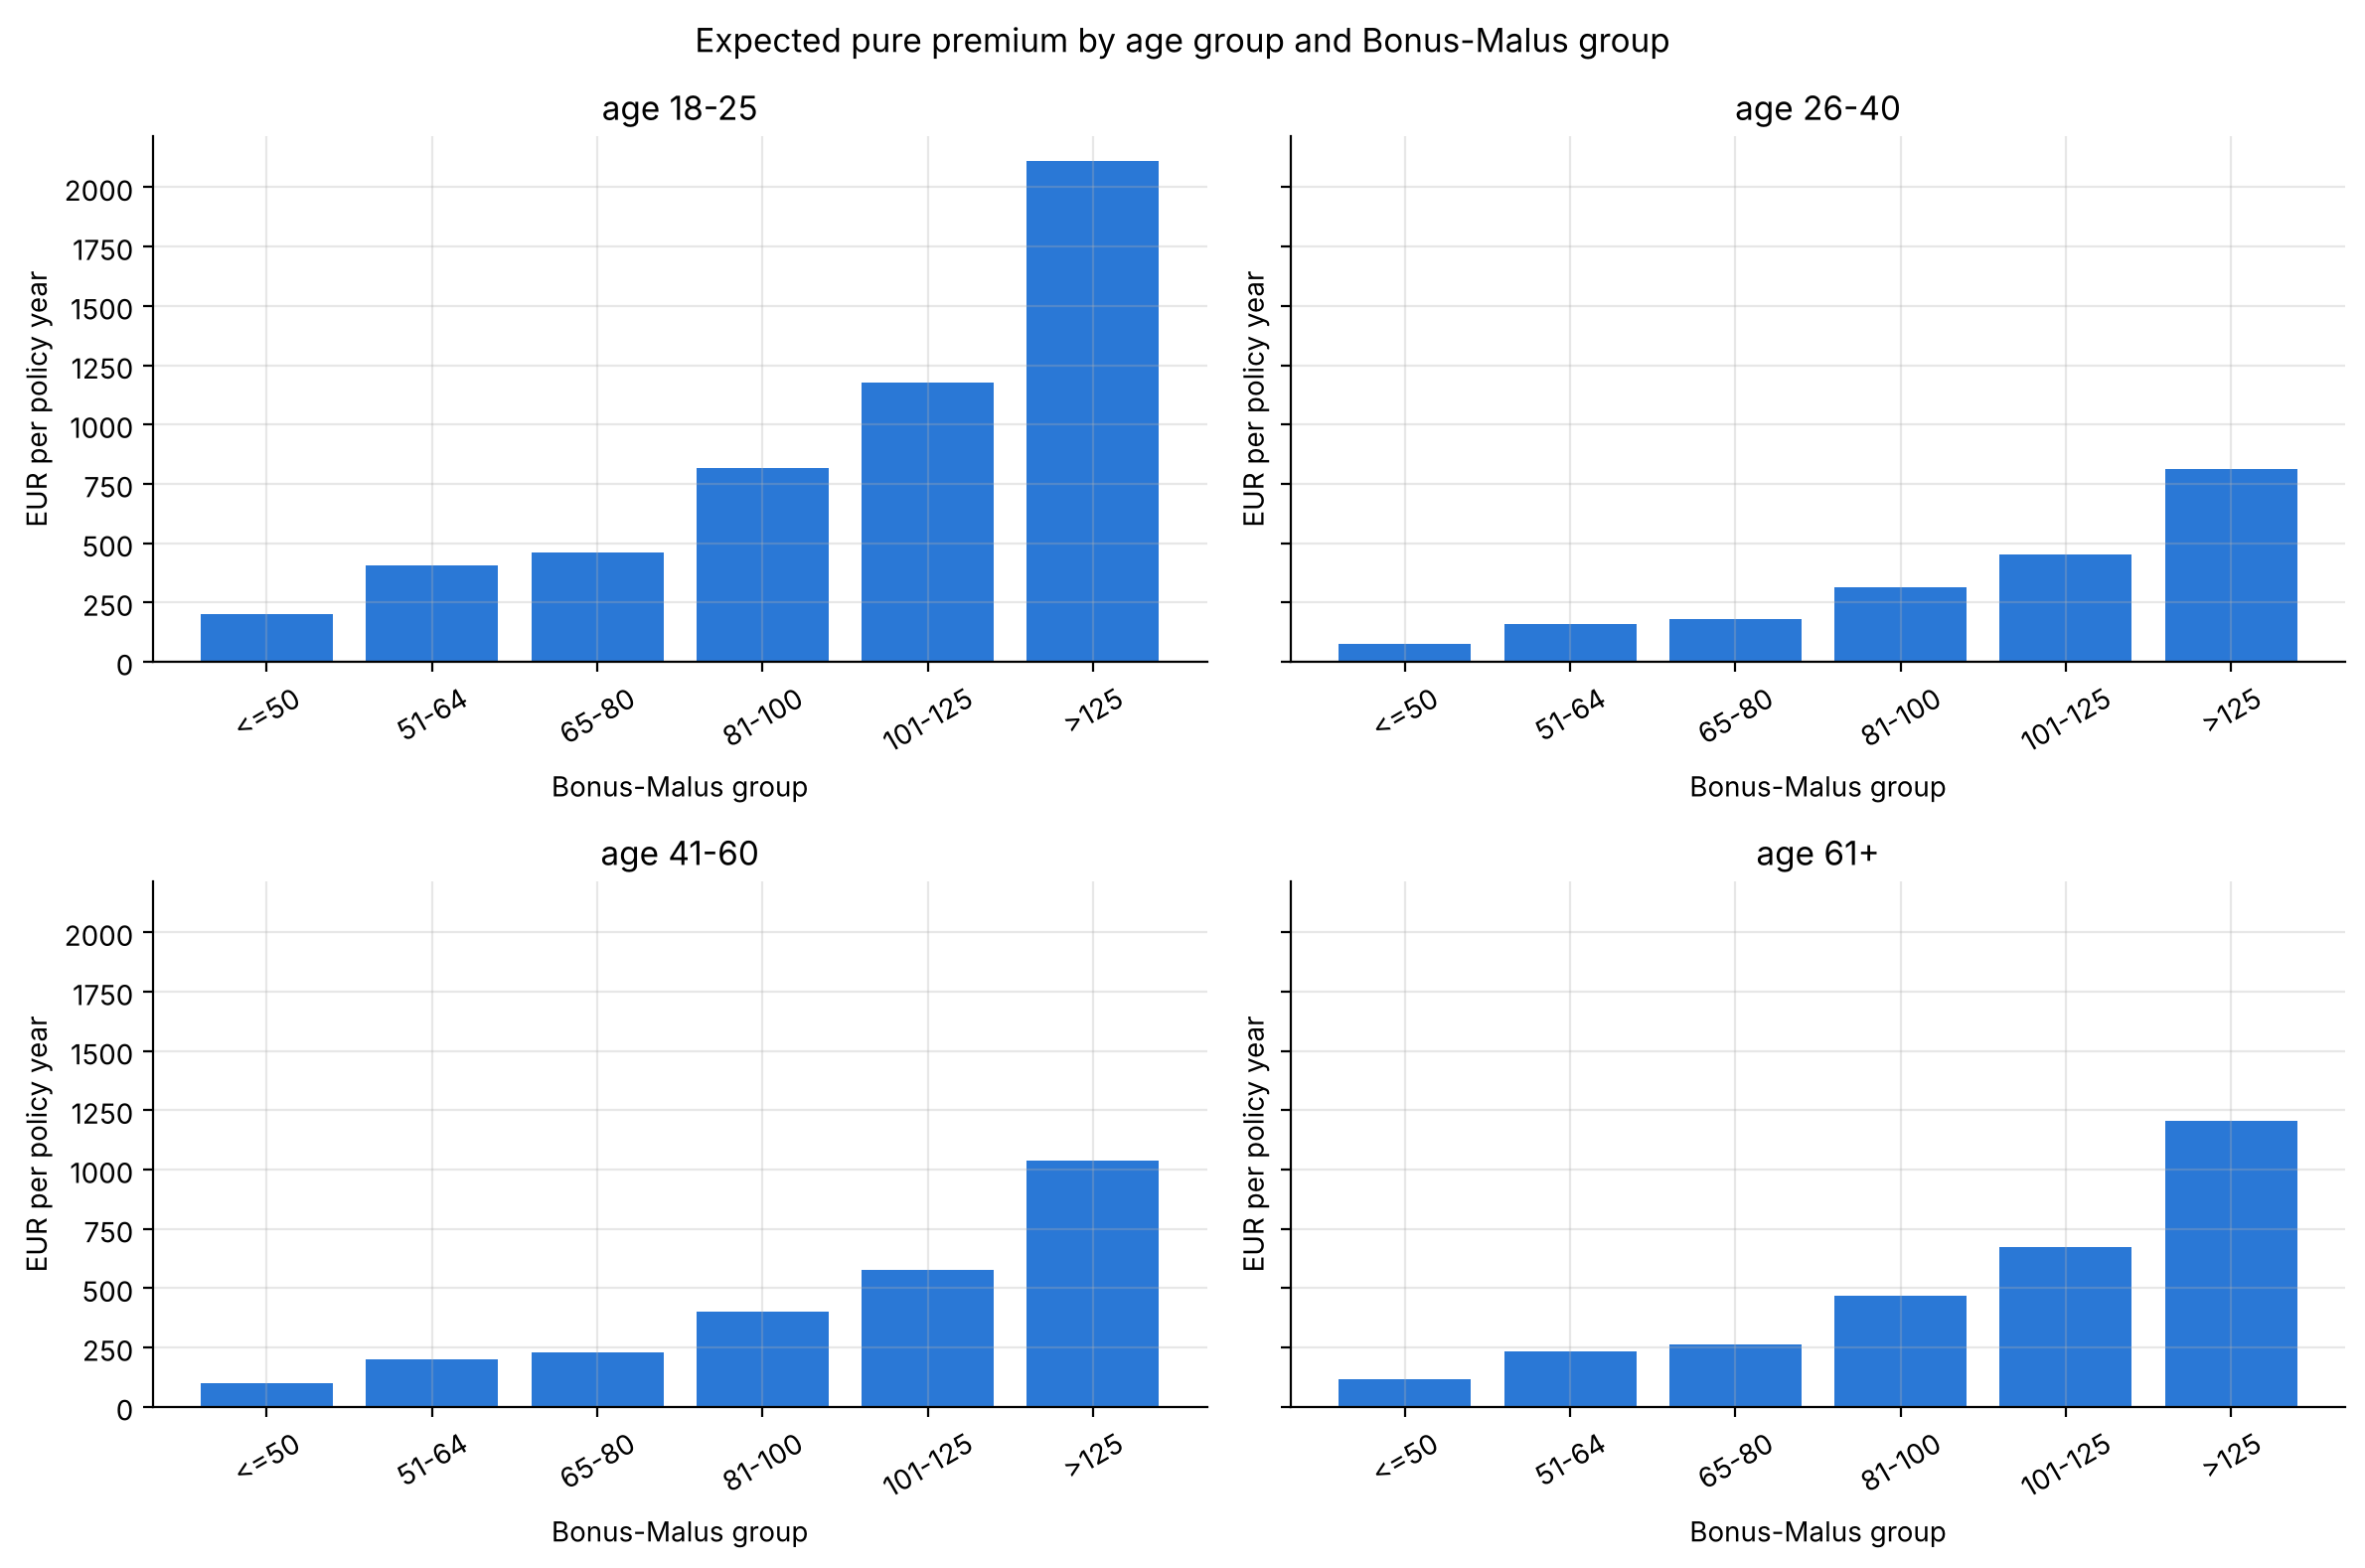


Tariff validation against observed claim costs
                    policies  pure_premium  observed_pure_premium  relative_error_%
age_group bm_group                                                                 
18-25     <=50          1108         199.2                  136.4              46.0
          51-64          940         407.3                  106.3             283.2
          65-80         9872         461.6                  159.3             189.8
          81-100       23769         815.2                 1151.4             -29.2
          101-125       2514        1174.8                  581.8             101.9
          >125           279        2109.0                 2897.7             -27.2
26-40     <=50         68506          76.8                   78.5              -2.1
          51-64        73821         157.1                  139.5              12.6
          65-80        54500         178.1                  200.8             -11.3
          81-100       33295

In [8]:
cells = pricing.tariff_table(policies, poisson_model, gamma_model, show)
summary = pricing.validate_tariff(cells, policies, claims)

Before the cleaning, the portfolio error was +31.9%; now it is close to 0.
**This is not evidence of predictive quality**: a Poisson GLM with log link reproduces the total
claim count exactly on the data it was fitted on, the Gamma GLM nearly the total claim amount.
It only shows that frequency and severity data are consistent. Predictive quality needs data
the model has not seen.

## 6. Out-of-sample validation

80% of the policies are used for fitting, 20% for testing (random split with a fixed seed;
a split by policy number would be biased, because the policy number is related to the
claim frequency — see `policies_analysis.sql`, chapter 4.7).

- **D²**: share of the Poisson deviance of a no-factor model that the tariff explains.
  Values of a few percent are normal for claim counts — whether a policy has a claim at all
  is mostly chance.
- **Gini index**: how well the tariff ranks risks (0 = not at all).

In [9]:
train, test, train_c, test_c = split_by_policy(policies, claims)
null_model, base_model = fit_frequency(train, "ClaimNb ~ 1"), fit_frequency(train)

def test_metrics(model):
    rate = model.predict(test)
    d = poisson_deviance(test["ClaimNb"], rate * test["Exposure"])
    d0 = poisson_deviance(test["ClaimNb"], null_model.predict(test) * test["Exposure"])
    return 100 * (1 - d / d0), gini(test["ClaimNb"], rate, test["Exposure"])[0]

d2, g = test_metrics(base_model)
print(f"base model (age group + Bonus-Malus group) on the test set: D2 = {d2:.2f}%, Gini = {g:.3f}")

base model (age group + Bonus-Malus group) on the test set: D2 = 3.99%, Gini = 0.254


**Large losses dominate the portfolio check.** `validation.py` repeats the comparison of
modelled and observed claim cost on 5 held-out folds. With all claims, a single €4 million claim
moves the result of a fold by about 20 percentage points; with claims capped at €50,000 the error
stays within a few percent. This is why pricing caps large claims and charges the excess as a
separate loading — and why one test split is not enough to judge a model.

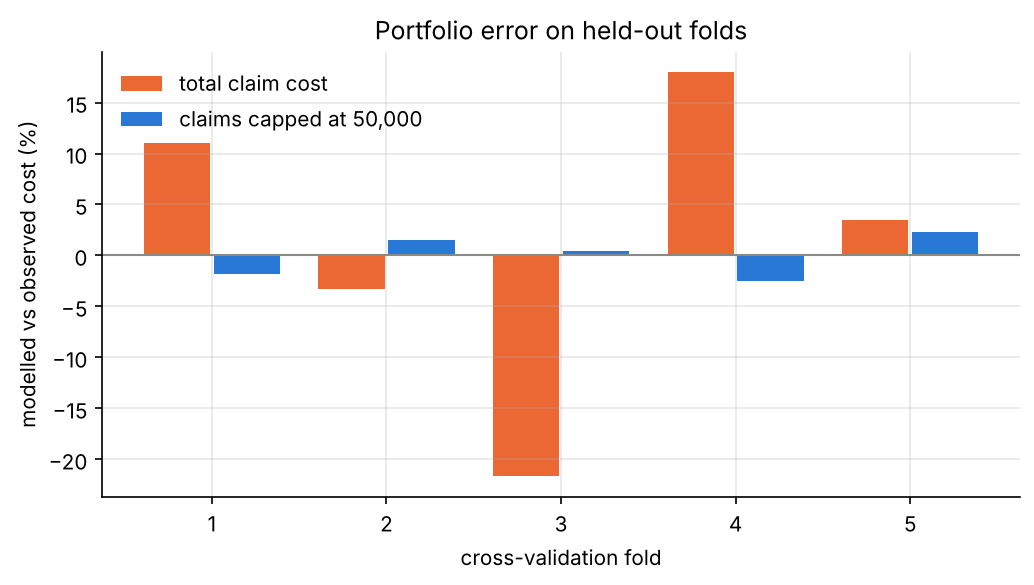

In [10]:
display(Image("figures/cv_portfolio_error.png"))   # created by validation.py

Two more results of `validation.py`:

- **Overdispersion** is tested with a Negative Binomial model: it is statistically significant,
  but small in size, and the tariff factors hardly change — it affects standard errors, not premiums.
- **The severity effect of young drivers is made of large losses**: with claims capped at €50,000,
  the age factors of the Gamma GLM are close to 1 and no longer significant. Young drivers do not
  cause more expensive ordinary claims; they cause large claims more often.

## 7. Additional rating factors

`features.py` selects further factors by **5-fold cross-validation on the training data only**
(a factor must lower the held-out deviance by at least 0.1% and in every fold), and uses the
test set exactly once. Selected: population density, vehicle brand, vehicle age and finer
driver-age bands. Comparison on the test set:

extended model on the test set: D2 = 4.68%, Gini = 0.289


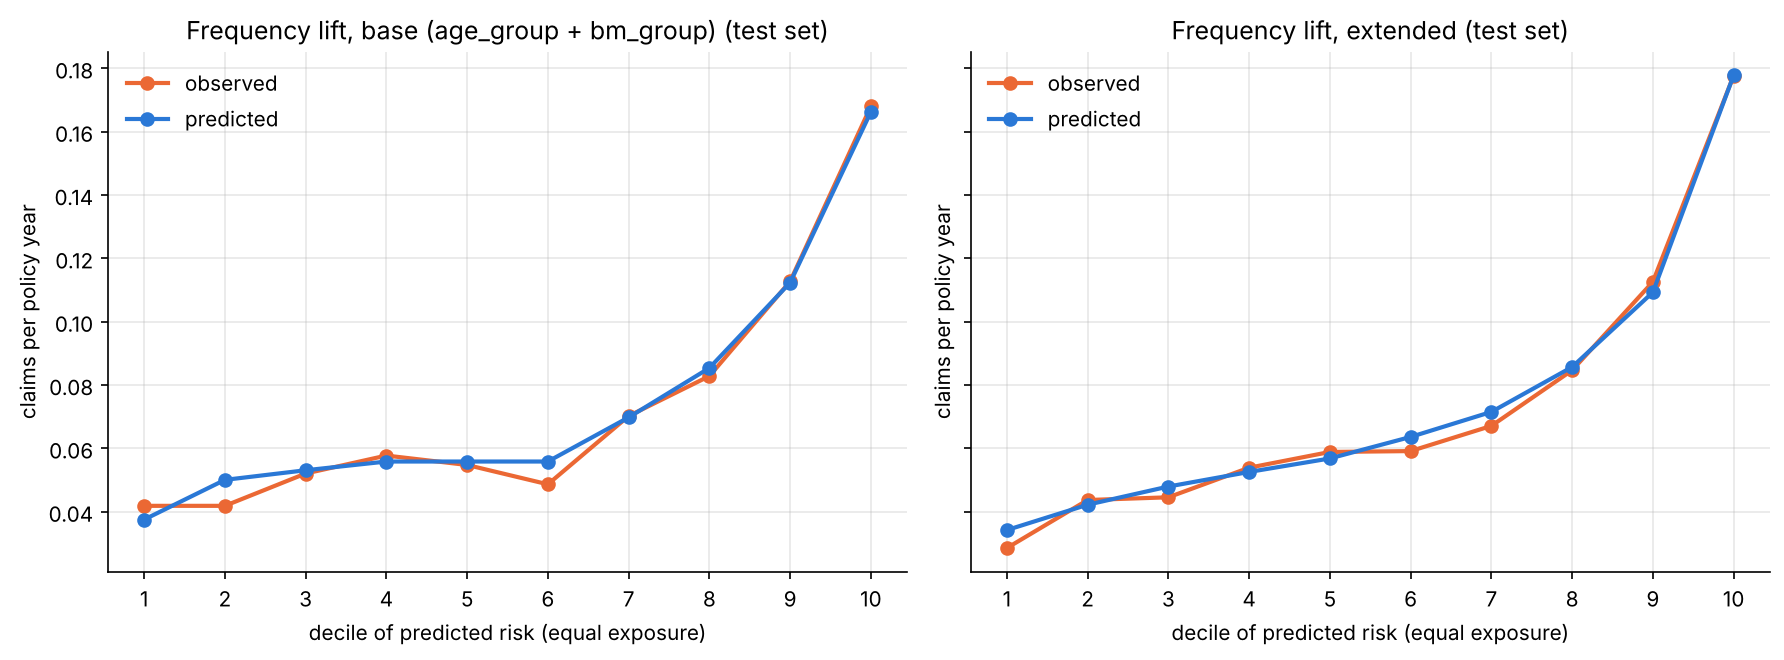

In [11]:
policies_ext = data_prep.add_rating_features(policies)
train_ext, test_ext, _, _ = split_by_policy(policies_ext, claims)
regions = data_prep.small_levels(train_ext, "Region")
train_ext, test_ext = (data_prep.group_small_regions(d, regions) for d in (train_ext, test_ext))

# result of the forward selection in features.py
selected = ["drivage_band", "bm_group", "density_band", "VehBrand", "vehage_band"]
extended_model = fit_frequency_agg(train_ext, selected)

rate = extended_model.predict(test_ext)
d = poisson_deviance(test_ext["ClaimNb"], rate * test_ext["Exposure"])
d0 = poisson_deviance(test_ext["ClaimNb"], null_model.predict(test_ext) * test_ext["Exposure"])
print(f"extended model on the test set: D2 = {100 * (1 - d / d0):.2f}%, "
      f"Gini = {gini(test_ext['ClaimNb'], rate, test_ext['Exposure'])[0]:.3f}")
display(Image("figures/lift_base_vs_extended.png"))   # created by features.py

`features.py` also spreads the large-loss excess over the tariff in two ways — uniformly and
**credibility-weighted by age group** ($Z = \min(1, \sqrt{n/1082})$, limited-fluctuation
standard) — and prints tariff tables averaged over the real portfolio mix:

In [12]:
tables = pd.read_csv("tariff_tables.csv")   # created by features.py
for name in ["portfolio mix (uniform loading)", "portfolio mix (credibility loading)"]:
    print(name)
    display(tables[tables["table"] == name]
            .pivot(index="age_group", columns="bm_group", values="pure_premium")
            .round(0)[["<=50", "51-64", "65-80", "81-100", "101-125", ">125"]])

portfolio mix (uniform loading)


bm_group,<=50,51-64,65-80,81-100,101-125,>125
age_group,,,,,,
18-25,118.0,198.0,237.0,411.0,861.0,1374.0
26-40,85.0,165.0,202.0,286.0,618.0,1051.0
41-60,118.0,245.0,306.0,432.0,933.0,1615.0
61+,116.0,242.0,300.0,432.0,942.0,1641.0


portfolio mix (credibility loading)


bm_group,<=50,51-64,65-80,81-100,101-125,>125
age_group,,,,,,
18-25,132.0,221.0,265.0,460.0,962.0,1536.0
26-40,84.0,164.0,200.0,284.0,613.0,1043.0
41-60,115.0,239.0,299.0,422.0,912.0,1578.0
61+,116.0,242.0,300.0,431.0,941.0,1639.0


## Conclusions and limitations

- The largest error of the first model came from **inconsistent data**, not from the model.
  Checking that frequency and severity describe the same claims is the first step of any tariff.
- Claim frequency is predictable and the extended tariff ranks risks clearly better out-of-sample.
  Claim severity is hardly predictable with these factors; its differences come from large losses.
- **Large losses** need their own treatment (capping, loading, credibility); a single claim can
  move a portfolio result by 20 percentage points.

**Limitations and next steps:** age × Bonus-Malus interaction (the same Bonus-Malus class means
different things at different ages), a separate large-loss model, the unexplained data block
and the implausible Bonus-Malus 50 at age 18 should be clarified with the data provider,
and no time information is available (no trend, no claims development).